### importing the librabries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler



##### Loading the Dataset

In [ ]:

df = pd.read_csv("Bengaluru_House_Data.csv")

#### Getting information about the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [ ]:

df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [5]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [6]:
df.shape

(13320, 9)

In [7]:

print("Missing Values (Before Cleaning):\n")
print(df.isnull().sum())

Missing Values (Before Cleaning):

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64


### Preprocess size and total_sqft

In [8]:

df['bhk'] = df['size'].apply(lambda x: str(x).split(' ')[0] if pd.notnull(x) else None)
df['bhk'] = pd.to_numeric(df['bhk'], errors='coerce')

def convert_sqft(x):
    try:
        if '-' in x:
            tokens = x.split('-')
            return (float(tokens[0]) + float(tokens[1])) / 2
        return float(x)
    except:
        return None

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df = df.dropna(subset=['total_sqft', 'bath', 'bhk'])
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']

### Handling the Missing Value

In [9]:

df.dropna(subset=['location', 'size', 'bhk', 'total_sqft'], inplace=True)
df.drop(columns=['society'], inplace=True)# Drop 'society' column due to high % of missing values
df['bath'] = df.groupby('bhk')['bath'].transform(lambda x: x.fillna(x.median()))
df['balcony'] = df['balcony'].fillna(df['balcony'].median())# Fill missing 'balcony' values with overall median
print("\nMissing Values (After Cleaning):\n")
print(df.isnull().sum())


Missing Values (After Cleaning):

area_type         0
availability      0
location          0
size              0
total_sqft        0
bath              0
balcony           0
price             0
bhk               0
price_per_sqft    0
dtype: int64


### Removing the outliers

In [10]:

df = df[df['price'] < 200]
df = df[df['total_sqft'] / df['bhk'] >= 300]
df['price_per_sqft'] = (df['price'] * 100000) / df['total_sqft']
mean_pps = df['price_per_sqft'].mean()
std_pps = df['price_per_sqft'].std()
df = df[(df['price_per_sqft'] > (mean_pps - 2 * std_pps)) & (df['price_per_sqft'] < (mean_pps + 2 * std_pps))]
df = df[df['bath'] < df['bhk'] + 2]

In [11]:
# Value counts
area_type_counts = df['area_type'].value_counts()
availability_counts = df['availability'].value_counts()
top_locations = df['location'].value_counts().head(10)

summary = df.describe()

missing_values = df.isnull().sum()

print("\n----- Missing Values -----")
print(missing_values)
print("\n----- Area Type Counts -----")
print(area_type_counts)
print("\n----- Availability Status -----")
print(availability_counts)
print("\n----- Top 10 Locations by Listings -----")
print(top_locations)


----- Missing Values -----
area_type         0
availability      0
location          0
size              0
total_sqft        0
bath              0
balcony           0
price             0
bhk               0
price_per_sqft    0
dtype: int64

----- Area Type Counts -----
area_type
Super built-up  Area    7925
Built-up  Area          1963
Plot  Area               590
Carpet  Area              72
Name: count, dtype: int64

----- Availability Status -----
availability
Ready To Move    8161
18-Dec            266
18-May            256
18-Apr            234
18-Aug            188
                 ... 
15-Oct              1
16-Sep              1
20-May              1
14-Nov              1
14-Jul              1
Name: count, Length: 78, dtype: int64

----- Top 10 Locations by Listings -----
location
Whitefield               435
Sarjapur  Road           329
Electronic City          287
Kanakpura Road           258
Thanisandra              226
Yelahanka                190
Uttarahalli              1

### Data visualization

#### Distribution of Area

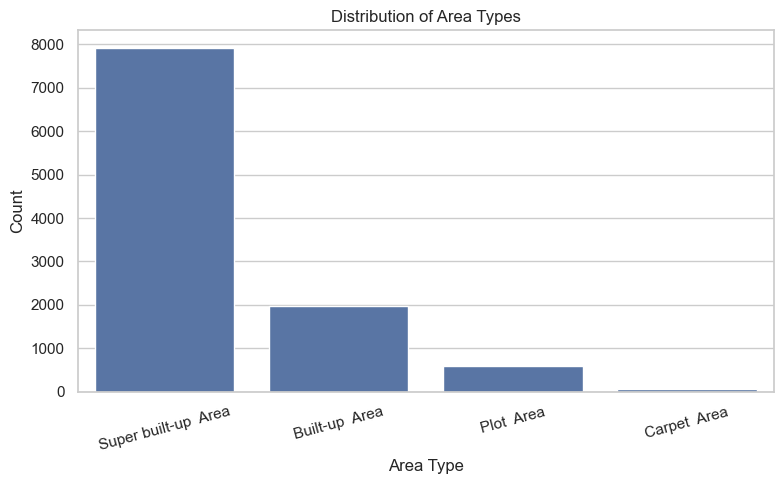

In [12]:
sns.set(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='area_type', order=df['area_type'].value_counts().index)
plt.title('Distribution of Area Types')
plt.xlabel('Area Type')
plt.ylabel('Count')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Distribution of BHKs 

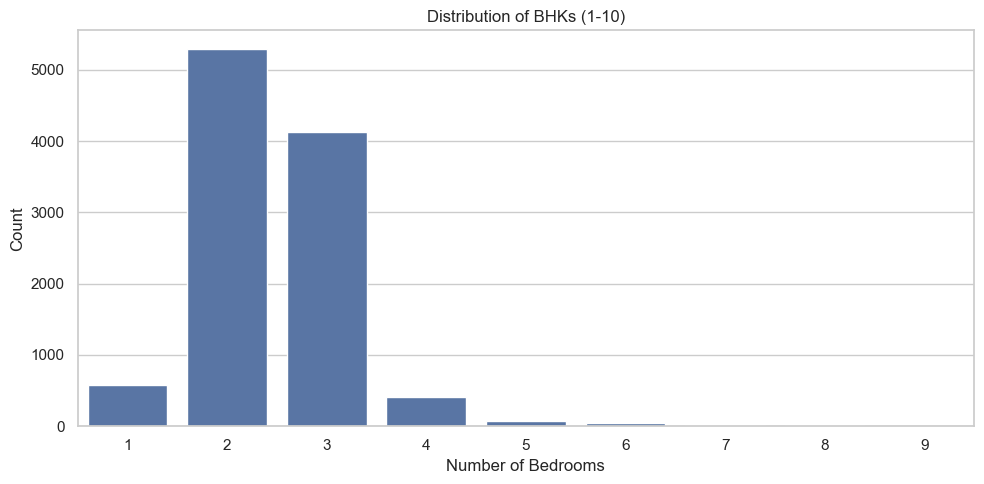

In [13]:
plt.figure(figsize=(10, 5))
# Convert BHK values to integers for cleaner x-axis
sns.countplot(x=df[df['bhk'] <= 10]['bhk'].astype(int), data=df[df['bhk'] <= 10])
plt.title('Distribution of BHKs (1-10)')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Distribuition of House Prices

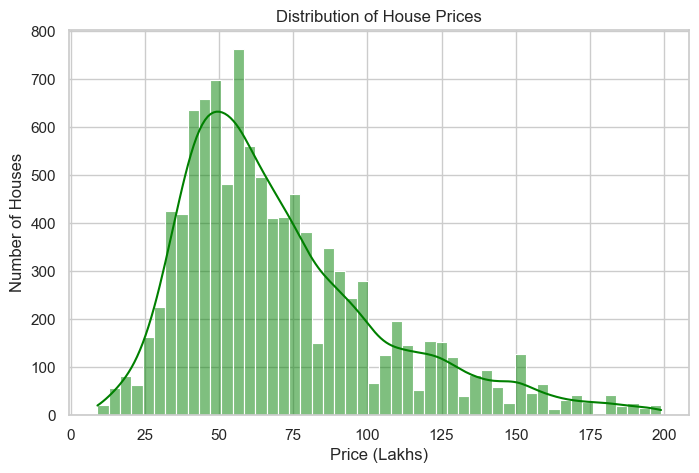

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['price'], bins=50, kde=True, color='green')
plt.title('Distribution of House Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Number of Houses')
plt.show()

### Top 10 locations

C:\Users\Victus\AppData\Local\Temp\ipykernel_19552\2263524685.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values, y=top_locations.index, palette='coolwarm')


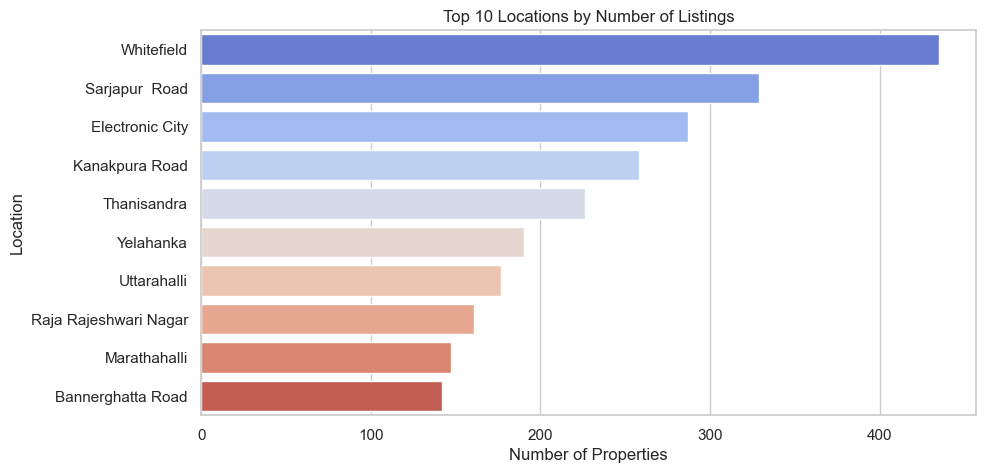

In [15]:
plt.figure(figsize=(10,5))
top_locations = df['location'].value_counts().head(10)
sns.barplot(x=top_locations.values, y=top_locations.index, palette='coolwarm')
plt.title("Top 10 Locations by Number of Listings")
plt.xlabel("Number of Properties")
plt.ylabel("Location")
plt.show()

#### Understanding the most relevant features  in my model

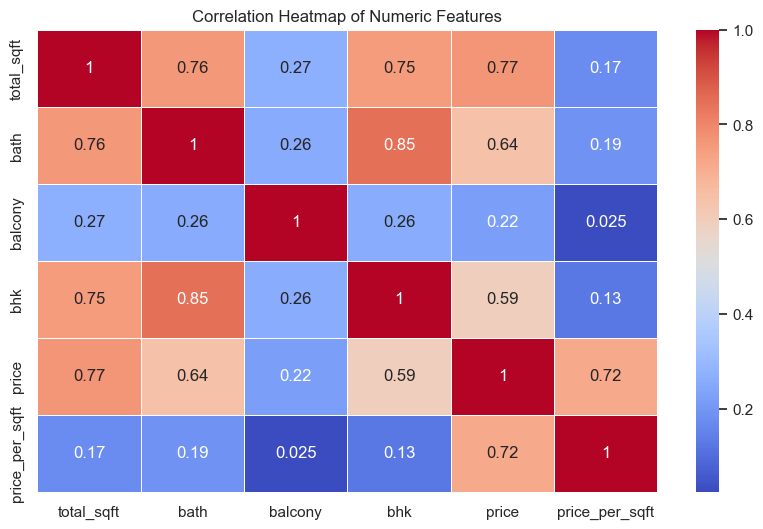

In [ ]:

features = ['total_sqft', 'bath', 'balcony', 'bhk', 'price', 'price_per_sqft']
corr_matrix = df[features].corr()


plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)# Heatmap
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


### Implement Linear Regression

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [18]:
# Reduce locations with low counts
location_counts = df['location'].value_counts()
locations_to_keep = location_counts[location_counts > 10].index
df['location'] = df['location'].apply(lambda x: x if x in locations_to_keep else 'Other')

In [19]:
# One-hot encoding
df = pd.get_dummies(df, columns=['location', 'area_type'], drop_first=True)

In [20]:
# Drop unnecessary columns
df.drop(columns=['availability', 'size'], inplace=True)
# Feature-Target split
X = df.drop('price', axis=1)
y = df['price']

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()# # Feature Scaling
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)



In [22]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

 Model Evaluation:
R² Score      : 0.9424233004590817
MAE           : 4.614591940734326
RMSE          : 8.449099984275716


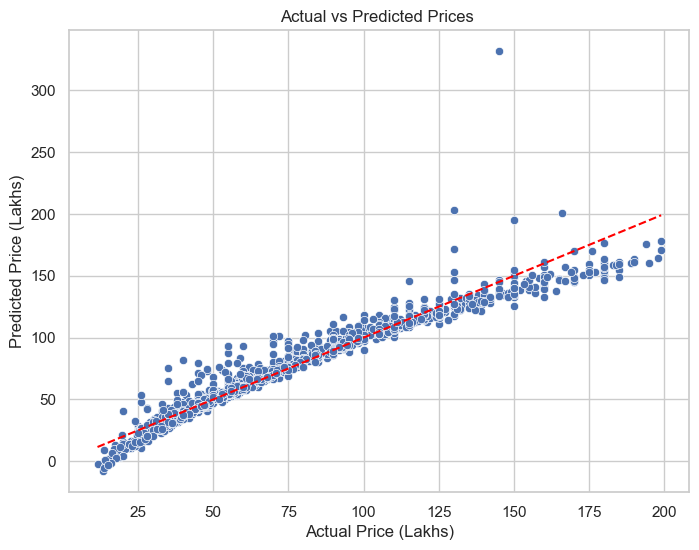

In [23]:
y_pred = model.predict(X_test)

print(" Model Evaluation:")
print("R² Score      :", r2_score(y_test, y_pred))
print("MAE           :", mean_absolute_error(y_test, y_pred))
print("RMSE          :", np.sqrt(mean_squared_error(y_test, y_pred)))

# Plot: Actual vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()


### implementing the model using DecisionTreeRegressor

Decision Tree
 R2 Score: 0.9500781951595316
MAE : 5.902003110485355
RMSE: 7.867417643714242


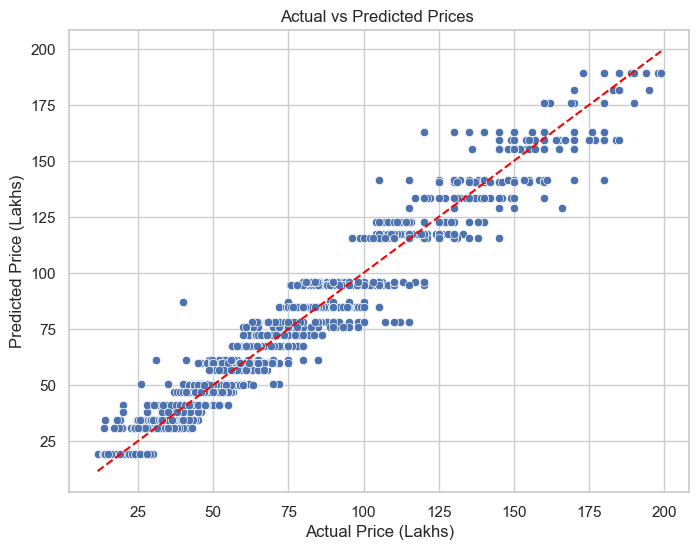

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(
max_depth=5,min_samples_split=20,min_samples_leaf=10,random_state=42
)

dt_model.fit(X_train, y_train)


y_pred = dt_model.predict(X_test)##Predict and evaluate
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("Decision Tree\n R2 Score:", r2)
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", rmse)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()

### implementing the model using Random Forest Regressor

R2 Score: 0.9974933095602995
MAE : 0.6744917034436385
RMSE: 1.7629395409422506


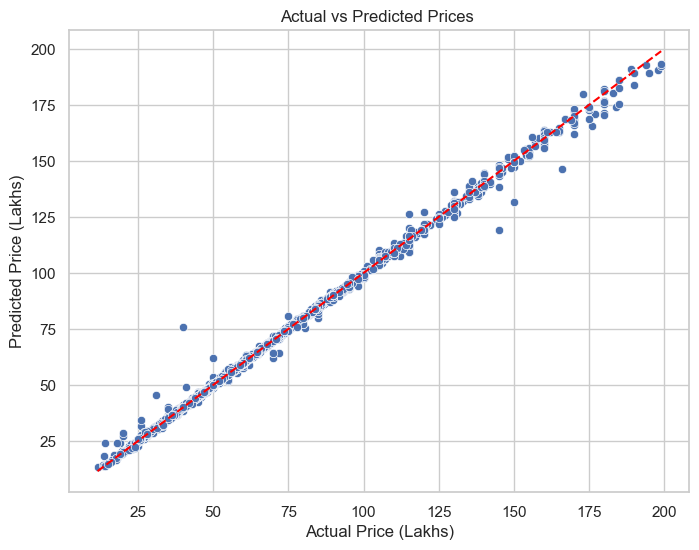

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Train Random Forest Regressor
# model = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)


rt_model = RandomForestRegressor(
    n_estimators=200,             
    max_depth=15,                  
    min_samples_split=15,         
    min_samples_leaf=5,           
    # max_features='sqrt',          
    random_state=42
)
rt_model.fit(X_train, y_train)


# Predict and Evaluate
y_pred = rt_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse =np.sqrt(mean_squared_error(y_test, y_pred))

print("R2 Score:", r2)
print("MAE :",mean_absolute_error(y_test,y_pred))
print("RMSE:", rmse)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()



R2 Score: 0.839463619674659
MAE : 9.710755915098577
RMSE: 14.108271205971187


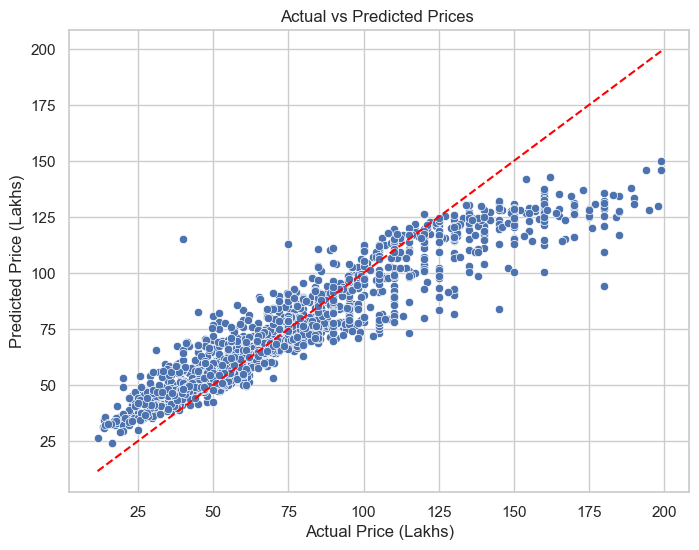

In [26]:
rt_model = RandomForestRegressor(
    n_estimators=200,              
    max_depth=15,                  
    min_samples_split=15,         
    min_samples_leaf=5,           
     max_features='sqrt',          
    random_state=42
)
rt_model.fit(X_train, y_train)


# Predict and Evaluate
y_pred = rt_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("R2 Score:", r2)
print("MAE :",mean_absolute_error(y_test,y_pred))
print("RMSE:", rmse)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()


#### Model optimization using Hyperparameter tuning on Random Forest

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Decision Tree params: {'max_depth': 9, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 5}
Best CV R2: 0.9906343918860901
R2_score: 0.9913636993513317
MAE: 1.8993972975924085
RMSE: 3.2722836519952603


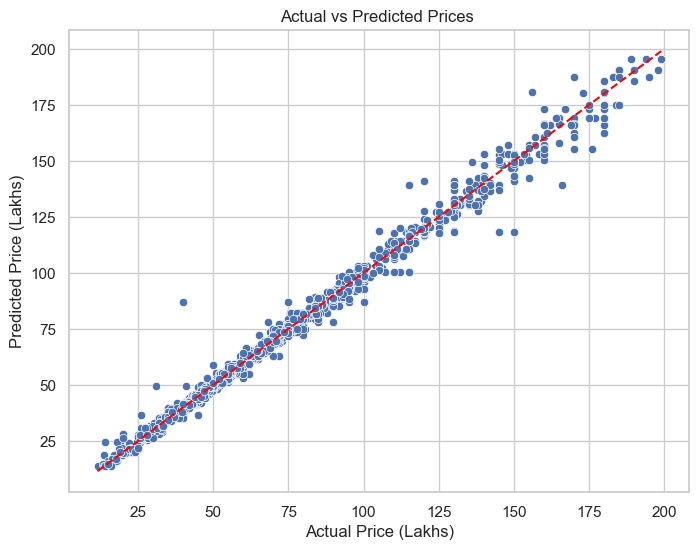

In [27]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
import numpy as np


# 1. Decision Tree hyperparameter tuning
dt_base = DecisionTreeRegressor(random_state=42)

dt_param_grid = {
    "max_depth": [3,5,7,9],
    "min_samples_split": [5,10,20],
    "min_samples_leaf": [10,20,40],
    "max_features": [None]
}

dt_grid = GridSearchCV(
    dt_base,
    dt_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)
print("Best Decision Tree params:", dt_grid.best_params_)
print("Best CV R2:", dt_grid.best_score_)

dt_best = dt_grid.best_estimator_
dt_pred = dt_best.predict(X_test)
print("R2_score:", r2_score(y_test, dt_pred))
print("MAE:", mean_absolute_error(y_test, dt_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, dt_pred)))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=dt_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()

#### Model optimization using Hyperparameter tuning on Random Forest

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best RF params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': None}
Best CV R2: 0.9970460680454721
R2_score: 0.9980902740780877
MAE:  2.3678008697012682
RMSE: 1.538766021752907


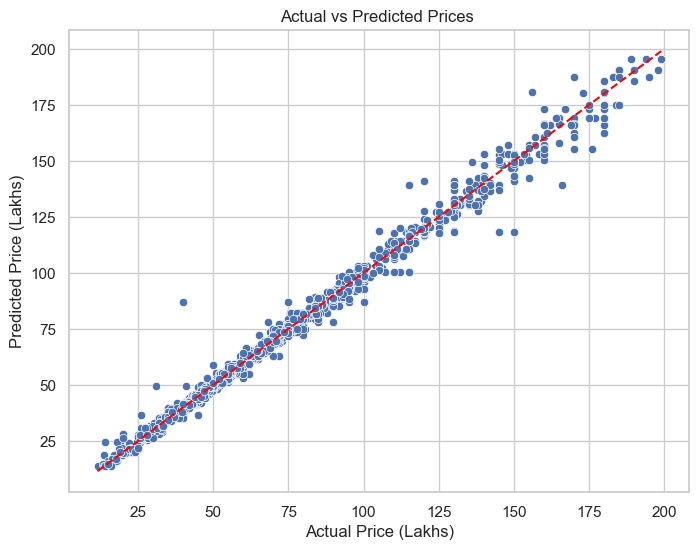

In [28]:
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_param_dist = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
}

rf_random = RandomizedSearchCV(
    rf_base,
    rf_param_dist,
    n_iter=40,            # you can increase to 80+ if training time is OK
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_random.fit(X_train, y_train)
print("Best RF params:", rf_random.best_params_)
print("Best CV R2:", rf_random.best_score_)

rf_best = rf_random.best_estimator_
rf_pred = rf_best.predict(X_test)
print("R2_score:", r2_score(y_test, rf_pred))
print("MAE: ",mean_squared_error(y_test,rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=dt_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Diagonal line
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Prices ")
plt.grid(True)
plt.show()

### Comparing the model performance


MODEL COMPARISON (WITH TUNED MODELS)
                Model  R2 Score   MAE   RMSE
Random Forest (Tuned)    0.9981 0.502  1.539
Decision Tree (Tuned)    0.9914 1.899  3.272
        Decision Tree    0.9501 5.902  7.867
    Linear Regression    0.9424 4.615  8.449
        Random Forest    0.8395 9.711 14.108



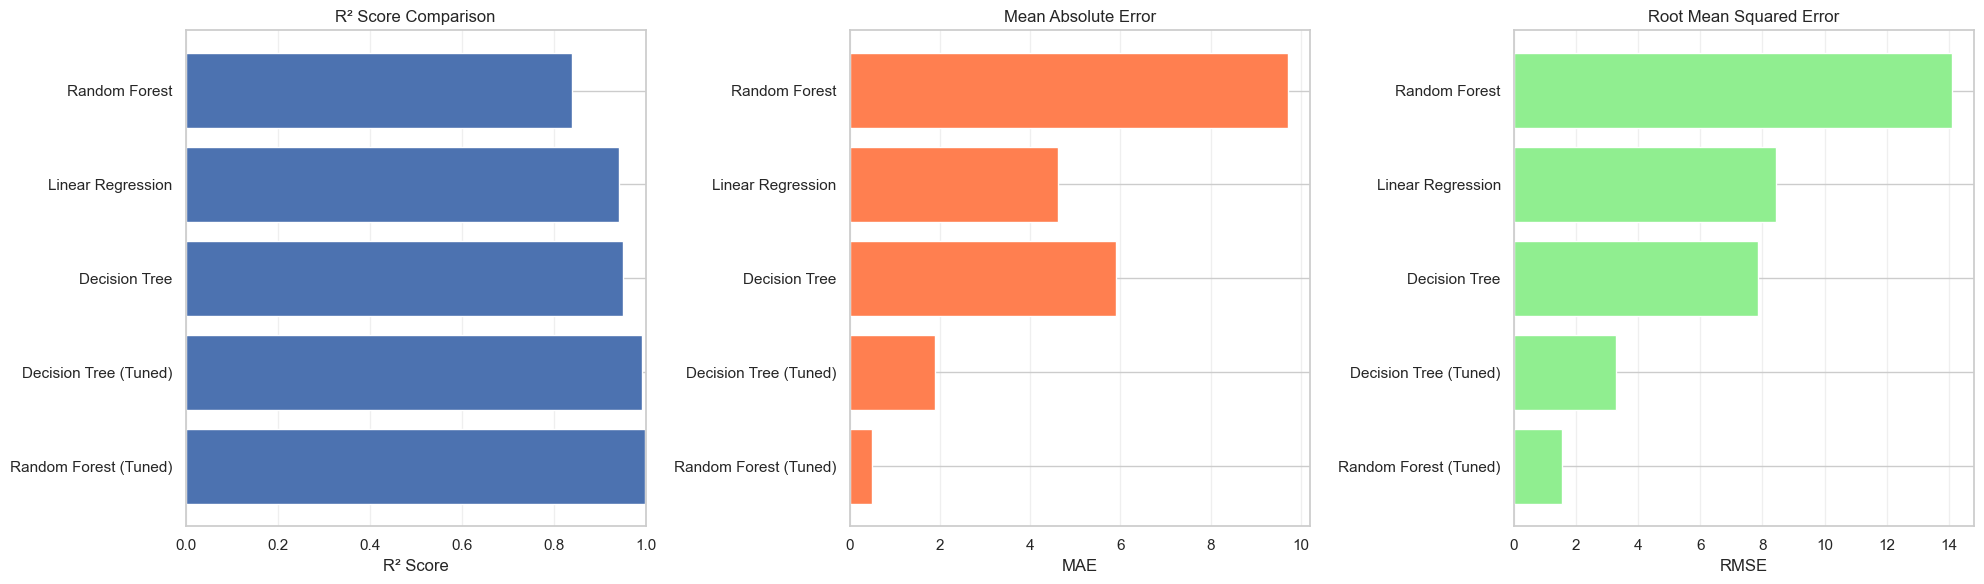

In [ ]:

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5,min_samples_split=20,min_samples_leaf=10,random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200,max_depth=15,min_samples_split=15,min_samples_leaf=5,max_features='sqrt',random_state=42),

   
    'Decision Tree (Tuned)': dt_best,
    'Random Forest (Tuned)': rf_best,
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    results.append({
        'Model': name,
        'R2 Score': round(r2, 4),
        'MAE': round(mae, 3),
        'RMSE': round(rmse, 3)
    })


comparison_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)# Convert to DataFrame

print("\n" + "="*70)
print("MODEL COMPARISON (WITH TUNED MODELS)")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70 + "\n")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ------------------------------------
# R² Score Comparison
# ------------------------------------
axes[0].barh(comparison_df['Model'], comparison_df['R2 Score'])
axes[0].set_xlabel('R² Score')
axes[0].set_title('R² Score Comparison')
axes[0].set_xlim(0, 1)
axes[0].grid(axis='x', alpha=0.3)

# ------------------------------------
# Mean Absolute Error Comparison
# ------------------------------------
axes[1].barh(comparison_df['Model'], comparison_df['MAE'], color='coral')
axes[1].set_xlabel('MAE')
axes[1].set_title('Mean Absolute Error')
axes[1].grid(axis='x', alpha=0.3)

# ------------------------------------
# Root Mean Squared Error Comparison
# ------------------------------------
axes[2].barh(comparison_df['Model'], comparison_df['RMSE'], color='lightgreen')
axes[2].set_xlabel('RMSE')
axes[2].set_title('Root Mean Squared Error')
axes[2].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(dt_grid, "dt_grid.joblib")# Save model 



['dt_grid.joblib']

In [ ]:

feature_names = X.columns.tolist()
joblib.dump(feature_names, "feature_names.joblib")# Save feature names for the web app

['feature_names.joblib']